# Kristiansund port entry planning


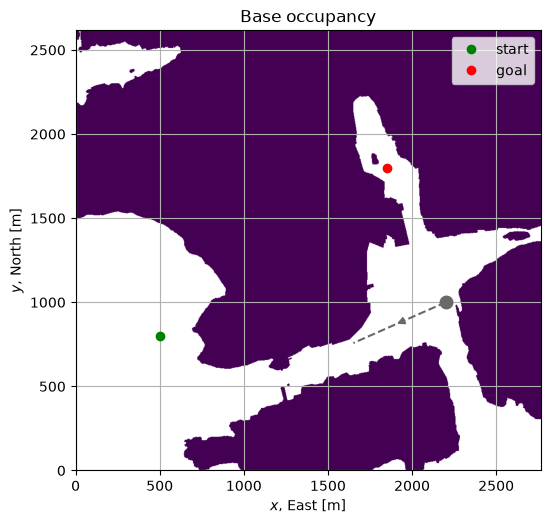

In [1]:
from cartoblobpy.graph import Graph
import matplotlib.pyplot as plt
from risk_informed_planner.obstacles import *
from risk_informed_planner.visualization import *
import numpy as np




g = Graph()
g.load_from_yaml("../maps/kristiansund_small_port_entry/map.yaml")
g.goal = (1850.0, 1800.0)
g.start = (500.0, 800.0)

obstacles = [
    LinearDynamicObstacle.create(start_pose=(2200.0, 1000.0), end_pose=(500.0, 250.0), velocity=1.5),
    # LinearDynamicObstacle.create(start_pose=(1500.0, 1100.0), end_pose=(250.0, 1100.0), velocity=3.0),
    # LinearDynamicObstacle.create(start_pose=(2200.0, 1800.0), end_pose=(5300.0, 4000.0), velocity=4.0),
    # LinearDynamicObstacle.create(start_pose=(2300.0, 1800.0), end_pose=(5400.0, 4000.0), velocity=5.0),
]

fig, ax = plt.subplots(figsize=(6, 6))


g.plot(ax=ax)
plot_obstacles(obstacles, ax=ax, max_time=400.0)
plt.grid(True)

In [2]:
from risk_informed_planner.licenses import pysmile_license
from risk_informed_planner.config import Config

from risk_informed_planner.planner import RiskAwareAngleCostRRTStarSearch
from risk_informed_planner.risk.dynamic_risk import DynamicRisk
from risk_informed_planner.risk import cost_model

from risk_informed_planner.utils import Node, smooth_path


start = Node(g.start[0], g.start[1], 0)
goal = Node(g.goal[0], g.goal[1], -1)


/opt/homebrew/Caskroom/miniconda/base/envs/sandbox3.13/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
import time
import numpy as np


max_nodes = 1500
cfg = Config(
    X_LIMITS=(0, g.width),
    Y_LIMITS=(0, g.height),
    STEP_SIZE=100,
    GOAL_RADIUS=75,
    NEIGHBOR_RADIUS=200,
    MAX_NODES=max_nodes,
    MAX_NEIGHBORS_RISK_RENEWAL=max_nodes,
    ALPHA=0.1,
    BETA=100.0,
    GAMMA=0.6,
    MAX_TURN_ANGLE=np.pi / 4.0,
    # RISK_CUTOFF=0.20,
    RISK_SAMPLE_SPACING=30.0,
    RISK_AGGREGATION="max"
)

min_depth=5.0
risk_model = DynamicRisk(
    max_distance_from_shore=150.0,
    lookahead_distance=150.0,
    graph=g,
    obstacles=obstacles,
    max_dcpa_for_collision_risk=50.0,
    max_tcpa_for_collision_risk=120.0,
    max_relative_velocity_for_collision_risk=6.0,
    grounding_depth_hard_limit=min_depth,
    desired_speed=3.0,
    cost_model=cost_model.NormalizedExpectedLoss(),
)
# cfg.RISK_CUTOFF=risk_model.cost_model.compute_worst_case_cost(risk_model.bbn_network) / 4.0
# cfg.BETA=risk_model.cost_model.compute_worst_case_cost(risk_model.bbn_network) * 2

path_planner = RiskAwareAngleCostRRTStarSearch(
    start=start,
    goal=goal,
    graph=g,
    cfg=cfg,
    risk_model=risk_model,
    # callback_functions=[],
    record_bbn_snapshots=True,
    min_depth=min_depth,
    free_check_method=RiskAwareAngleCostRRTStarSearch.FreeCheckMethod.DEPTH_SAMPLING_OCCUPANCY_CHECKS

)


In [4]:

start_time = time.perf_counter()
nodes, path = path_planner()
total_computation_time = time.perf_counter() - start_time
print(f"Planning completed in {total_computation_time:.2f} seconds.")

Progress:   0%|                                                                                                                                             | 0/1500 [00:00<?, ?node/s]

Progress:   0%|▏                                                                                                                         | 2/1500 [00:00<00:00, 79891.50node/s, Path=0]

Progress:   0%|▏                                                                                                                          | 3/1500 [00:00<00:00, 1719.45node/s, Path=0]

Progress:   0%|▎                                                                                                                          | 4/1500 [00:00<00:00, 1611.03node/s, Path=0]

Progress:   0%|▍                                                                                                                          | 5/1500 [00:00<00:01, 1312.36node/s, Path=0]

Progress:   0%|▍                                                                                                                          | 6/1500 [00:00<00:01, 1310.65node/s, Path=0]

... (1,606 outputs left out)

Progress: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▉| 1499/1500 [00:13<00:00, 54.38node/s, Path=25]

Progress: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1500/1500 [00:13<00:00, 54.38node/s, Path=25]

Progress: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1500/1500 [00:13<00:00, 108.06node/s, Path=25]

Planning completed in 13.95 seconds.


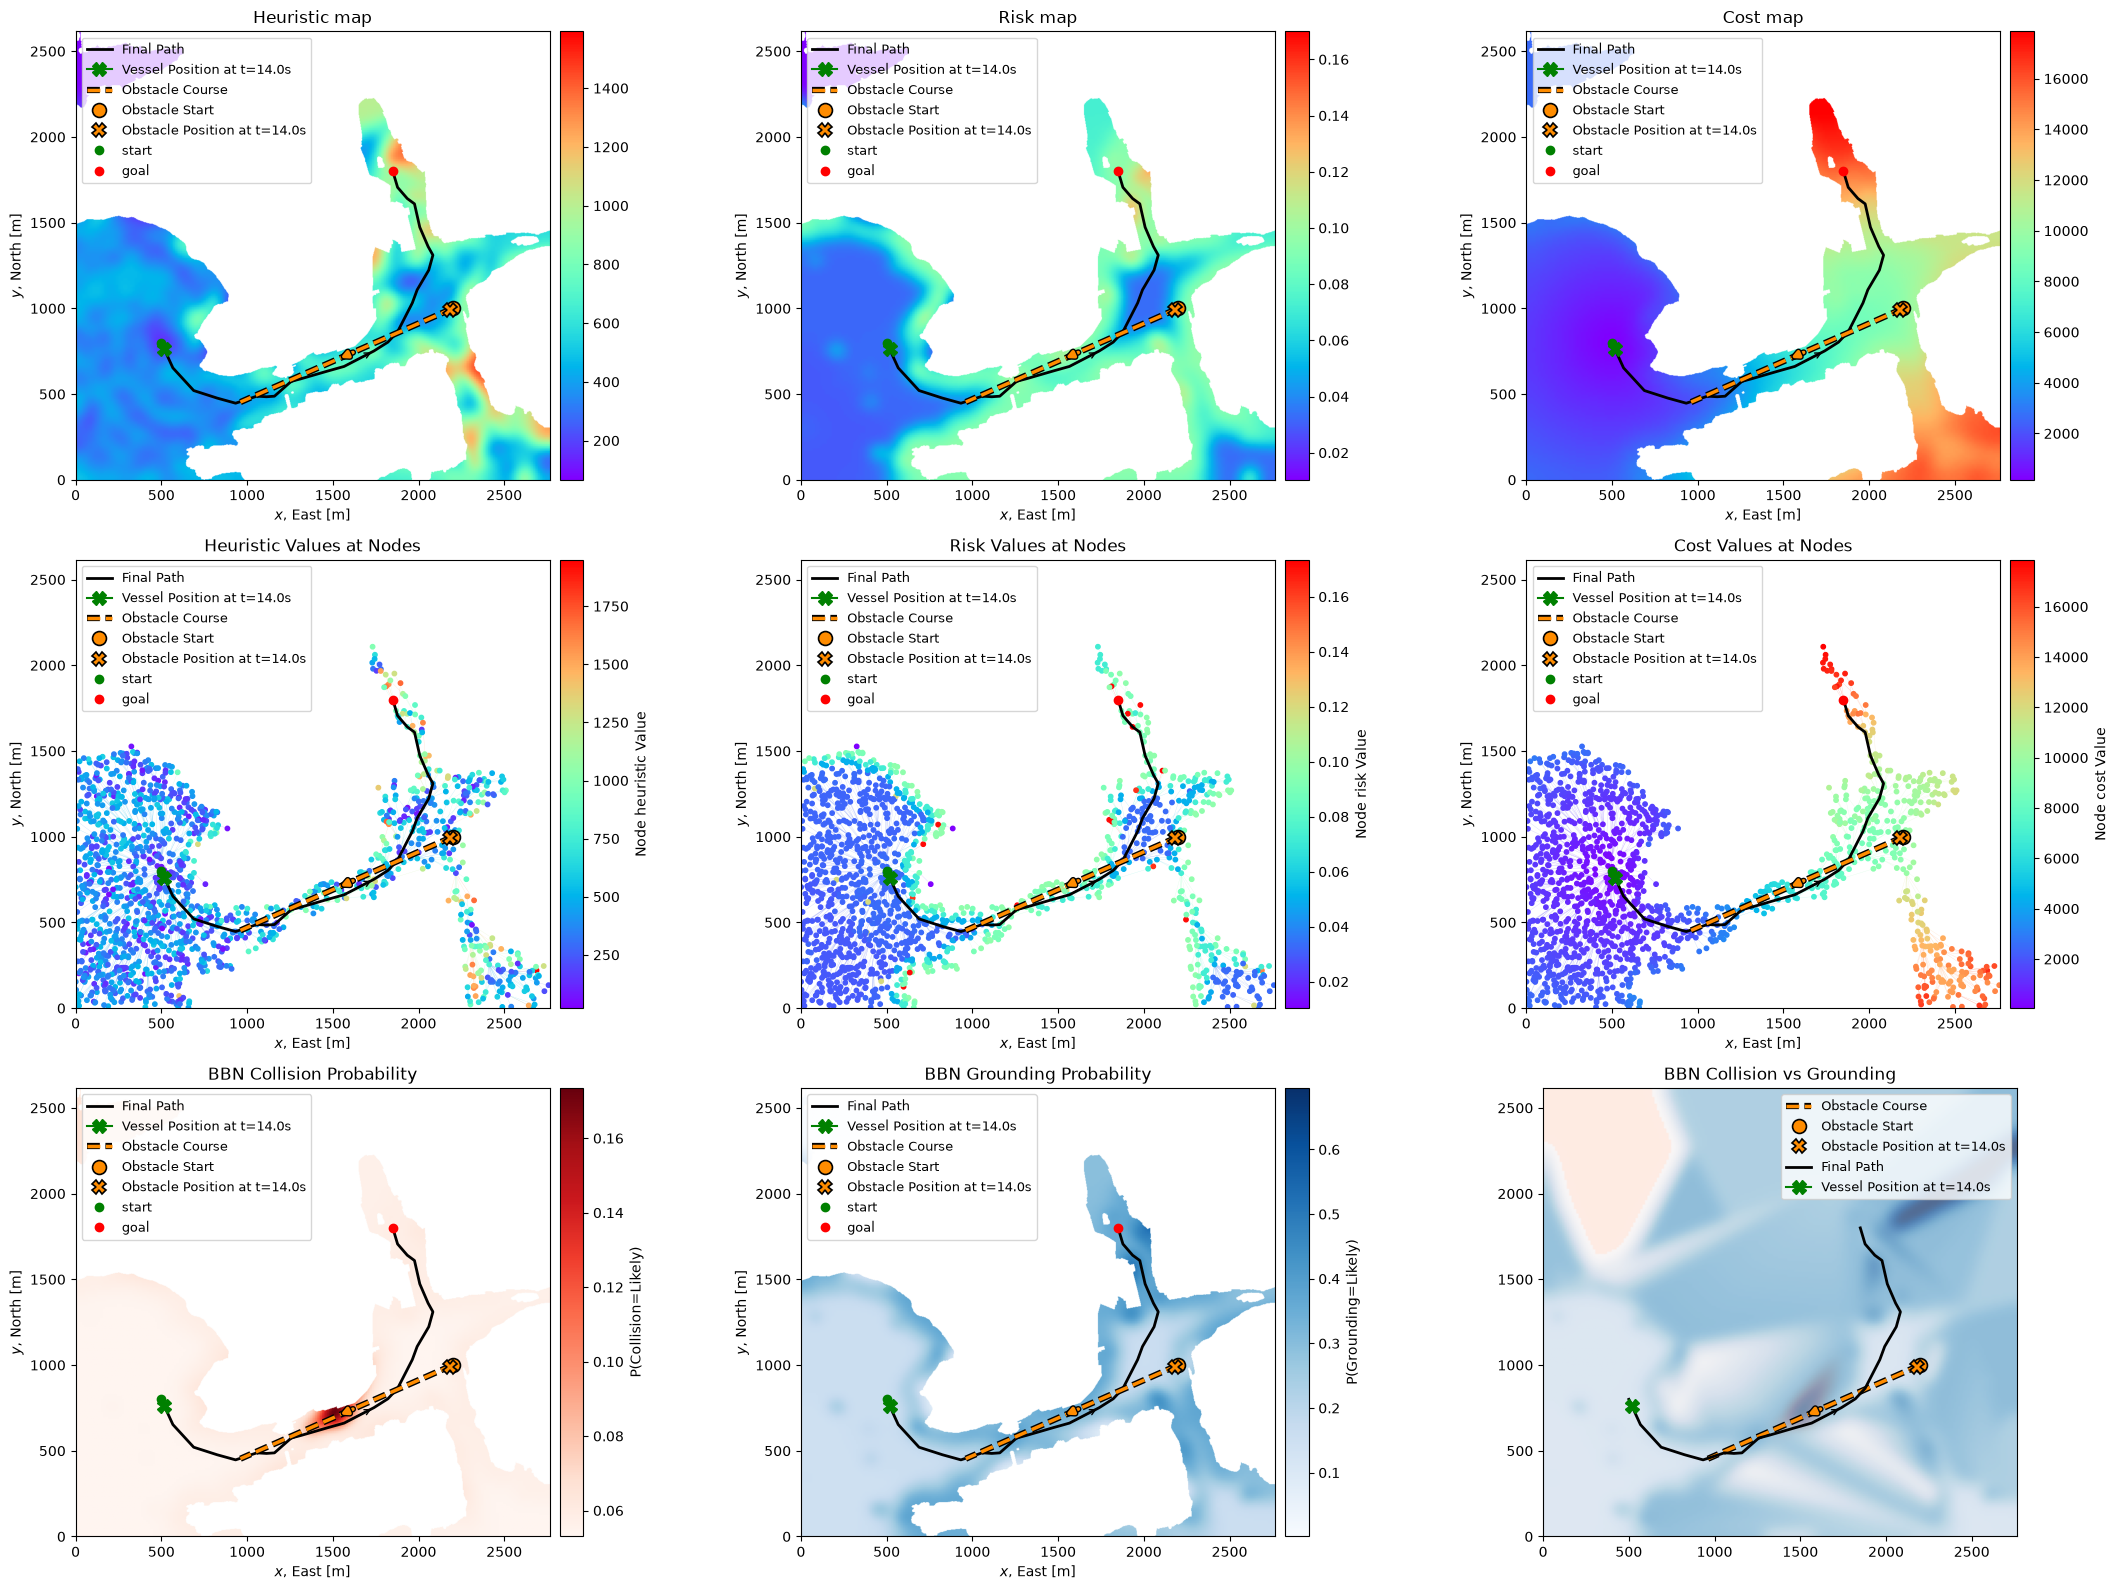

In [5]:
from risk_informed_planner.visualization import *

fig, ax = plt.subplots(3, 3, figsize=(22, 16))


axes = plot_matrix(
    nodes=nodes,
    obstacles=obstacles,
    path=path,
    cfg=cfg,
    graph=g,
    ax=ax,
    t_computation=total_computation_time,
    speed=risk_model.desired_speed
)
plt.savefig(f"plots/kristiansund_small_{type(risk_model.cost_model).__name__}_alpha_{cfg.ALPHA}_beta_{cfg.BETA}.pdf")